# Conservation of Energy in Supernova SN2023ixf: A Quantitative Analysis

## Abstract  

This Jupyter Notebook explores the principles of energy conservation applied to Supernova SN2023ixf. Using observational estimates and simplified models, we calculate and compare the main energy components released during the explosion: kinetic, radiant, and thermal. The aim is to evaluate how these contributions relate to the total explosion energy and to discuss the discrepancies between theoretical expectations and observationally derived values. This exercise highlights both the magnitude of the energetic processes involved in a supernova and the role of energy conservation as a fundamental tool for understanding extreme astrophysical phenomena.

This quantitative analysis uses data from the [article] “Multiband Simultaneous Photometry of Type II SN 2023ixf with Mephisto and the Twin 50-cm Telescopes.”

[article]: https://arxiv.org/pdf/2405.08327

## Learning Goals

By the end of this activity, you will be able to:

* Explain how energy is released and distributed in a core-collapse supernova.

* Use the Stefan–Boltzmann law with photospheric parameters to calculate the bolometric luminosity of SN 2023ixf.

* Estimate the ejecta mass from observational parameters such as plateau duration and luminosity.

* Calculate the kinetic, radiative, and thermal energies of a supernova and compare them with the canonical explosion energy (~10^51 erg).

* Assess whether energy is conserved by analyzing the balance between different energy components.

* Apply Python tools to process astrophysical data, perform calculations, and generate scientific plots.

## About SN 2023ixf

SN 2023ixf is a bright Type II supernova discovered in May 2023 in the Pinwheel Galaxy (M101), just 21 million light-years away. Because of its relative closeness and brightness, astronomers around the world quickly turned their telescopes toward it, making it one of the best-observed supernovae in recent years.


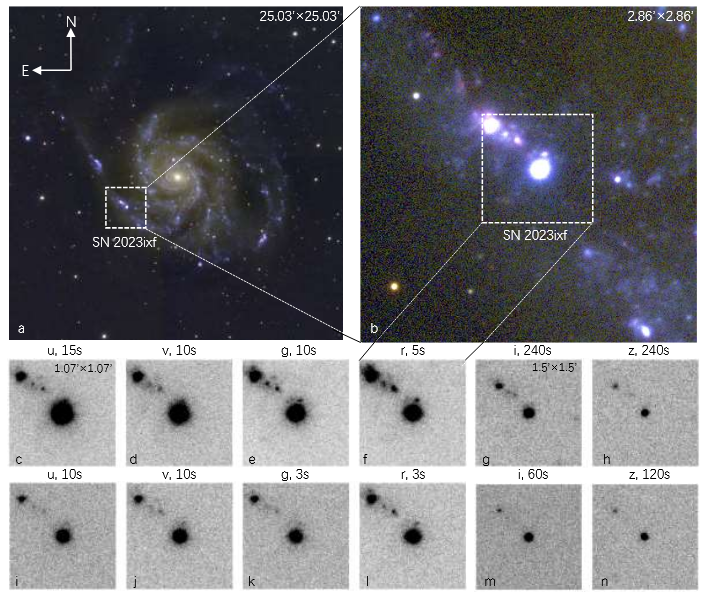

What makes SN 2023ixf especially exciting for scientists (and students like you!) is that we have high-quality, multi-band data starting only hours after the explosion. This gives us a rare chance to follow the supernova in detail, from its first flash of light through the plateau phase, when the expanding envelope cools but keeps shining steadily, all the way into its decline.

By studying this event, we can explore fundamental physics: how massive stars end their lives, how energy is transformed and conserved, and how the most powerful explosions in the universe enrich galaxies with heavy elements.

## Code Analysis

### Importing Libraries

In [ ]:
!wget https://raw.githubusercontent.com/jsuarez314/econservation_sn2023ixf/refs/heads/master/SN2023ixf_data.txt

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

In [ ]:
#function to read and split data and error
def split_value_error(cell):
    match = re.match(r"([\d.]+)\s*±\s*([\d.]+)", cell)
    if match:
        return float(match.group(1)), float(match.group(2))
    else:
        return np.nan, np.nan

### Reading the data file

In [ ]:
#Read data columns
filename = "SN2023ixf_data.txt"

raw = pd.read_csv(filename, delim_whitespace=True, header=1, names=["MJD", "logL", "logTeff", "logRph"])
df = pd.DataFrame()

raw.head()

In [ ]:
#Read data and its error
df["MJD"] = raw["MJD"]
df[["logL", "logL_err"]] = raw["logL"].apply(lambda x: pd.Series(split_value_error(x)))
df[["logTeff", "logTeff_err"]] = raw["logTeff"].apply(lambda x: pd.Series(split_value_error(x)))
df[["logRph", "logRph_err"]] = raw["logRph"].apply(lambda x: pd.Series(split_value_error(x)))

df["L_erg_s"] = 10 ** df["logL"]
df["Teff_K"] = 10 ** df["logTeff"]
df["Rph_cm"] = 10 ** df["logRph"]

In [ ]:
#Time laps
t_secs = (df['MJD'] - df['MJD'].min()) * 86400
t_days = df['MJD'] - df['MJD'].min()

# What is Bolometric Luminosity?

Bolometric luminosity is the total energy emitted by a star or a supernova per unit of time, across **all wavelengths**. It can be calculated using the Stefan–Boltzmann law:

$$ L = 4 \pi R_{ph}^2 \, \sigma \, T_{eff}^4 $$

Where:

- $L$: bolometric luminosity (erg/s)  
- $R_{ph}$: photospheric radius (cm)  
- $\sigma$: Stefan–Boltzmann constant  
- $T_{eff}$: effective temperature (K)


In [ ]:
# Stefan-Boltzmann constant in cgs
sigma = 5.670374419e-5  # erg cm^-2 s^-1 K^-4

log_Rph = df['logRph']
log_Teff = df['logTeff']

# Convert log to real values
Rph = 10 ** log_Rph  # cm
Teff = 10 ** log_Teff  # K

# Compute the Bolometric Luminosity for each time
L_bol = 4 * np.pi * Rph**2 * sigma * Teff**4  # erg/s

plt.scatter(t_days, L_bol)
plt.title("Bolometric Luminosity (erg/s):")
plt.xlabel("Time (days)")
plt.ylabel("Bolometric Luminosity (erg/s)")
plt.grid()
plt.show()

In [ ]:
print("Maximum Bolometric Luminosity: {L_bol_max:.2e} erg/s".format(L_bol_max=L_bol.max()))

# Empirical Formula for Ejecta Mass

A useful relation for Type II-P supernovae is:

$
M_{\rm ej} \propto L_{\rm bol}^{1/2} \cdot t_{\rm plateau}^2
$

This formula comes from simplified radiative diffusion models (Arnett-type) and is intended for approximate comparisons. To express the ejecta mass in solar masses, we use a scaling factor with physical units:

$
M_{\rm ej} (M_\odot) = \left( \frac{L_{\rm bol}}{10^{43} \, \rm erg/s} \right)^{1/2}
\cdot \left( \frac{t_{\rm plateau}}{100 \, \rm days} \right)^2 \cdot 10
$

Where:

- $L_{\rm bol}$ : peak bolometric luminosity (erg/s)  
- $t_{\rm plateau}$ : duration of the plateau (in days, typically 80–120 days for Type II-P SNe)


In [ ]:
# Estimate plateau duration (in days)
t_plateau = 90  # Taken from the article

# Apply the empirical formula
L_norm = L_bol / 1e43       # Normalize bolometric luminosity
t_norm = t_plateau / 100    # Normalize plateau duration

# Calculate ejecta mass (in solar masses)
Mej = (L_norm)**0.5 * t_norm**2 * 10

# Plot the estimated ejecta mass over time
plt.scatter(t_days, Mej)
plt.title("Estimated Ejecta Mass (M_sun)")
plt.xlabel("Time (days)")
plt.ylabel("Ejecta Mass (M_sun)")
plt.grid()
plt.show()

# Print the range of ejecta masses
print("Estimated ejecta mass range: {:.2f} - {:.2f} M_sun".format(Mej.min(), Mej.max()))

In [ ]:
# Calculate the maximum ejecta mass using the peak bolometric luminosity
Mej_max = np.sqrt(L_bol.max() / 1e43) * (t_plateau / 100)**2 * 10

# Print the result
print("Maximum ejecta mass: {:.2f} M_sun".format(Mej_max))

## Estimating the Typical Kinetic Energy of a Supernova Explosion

In this section, we will estimate the **kinetic energy of the explosion** using a simplified model of the star's core collapse. These steps follow the calculations from the reference document.

**Student Note:** By following these steps, you can see how astrophysicists justify the canonical value of $10^{51}$ erg for the kinetic energy of a supernova explosion using only basic physics concepts.

---

### Step 1: Estimate the Radius of the Iron Core

Before the collapse, the inner core of the star is mostly iron and will eventually form the neutron star. Using typical stellar structure conditions for a 15 $M_sun$ star (from Shapiro & Teukolsky, *Black Holes, White Dwarfs, and Neutron Stars*):

- Central density: $\rho_c \sim 3.7 \times 10^9 \, \rm g/cm^3$  
- Core mass: $M_c \sim 1.5 \, M_\odot$

From these values, we can estimate the core radius:

$
R_c \sim 700 \, \rm km
$

In [ ]:
# Constants in cgs units
G = 6.67430e-8        # Gravitational constant [cm^3 g^-1 s^-2]
M_sun = 1.989e33      # Solar mass [g]

# Core properties before collapse (from Shapiro & Teukolsky)
rho_c = 3.7e9         # Central density [g/cm^3]
M_c = 1.5 * M_sun     # Core mass [g]

# Estimate core radius using M = 4/3 * pi * R^3 * rho
R_c = (3 * M_c / (4 * np.pi * rho_c))**(1/3)  # [cm]
print(f"Estimated core radius: {R_c/1e5:.1f} km")  # Convert to km for readability

### Step 2: Estimate Gravitational Energy Released by Core Collapse

The core collapses to a neutron star of radius $R_{NS} \sim 10 \, \rm km$. By conservation of energy, the gravitational energy released is:

$
\Delta E = \frac{G M_c^2}{R_{NS}} - \frac{G M_c^2}{R_c}
$

- Most of this energy (\~99%) escapes as **neutrinos**.  
- A small fraction (\~1%) is converted into the **kinetic energy of the ejecta**, and an even smaller fraction (\~10^-4 erg) goes into **radiation**.  

This explains why the typical explosion energy is $E_{\rm kin} \sim 10^{51} \, \rm erg$.

### **Activity**:
* ***Complete the blank spaces by writing the equations used to estimate the kinetic and radiative energy.***

In [ ]:
R_ns = 10e5  # Neutron star radius [cm] = 10 km
Delta_E = ___________________  # [erg]

# Fraction of energy going to kinetic & radiative
E_kin = ________________  # ~1% goes to kinetic
E_rad = ________________  # ~0.01% goes to radiation
print(f"Gravitational energy released: {Delta_E:.2e} erg")
print(f"Typical kinetic energy of ejecta: {E_kin:.2e} erg")
print(f"Typical radiative energy: {E_rad:.2e} erg")

### Step 3: Energy to Unbind the Stellar Envelope

To verify that the explosion can unbind the outer layers, we estimate the gravitational binding energy of the envelope:

$
E_{\rm core-envelope} \sim \frac{G M_c M_{\rm ejecta}}{R_{\rm star}}
$

This shows that the energy released during the collapse is **more than enough to eject the outer layers**, confirming that the kinetic energy we observe is physically reasonable.

In [ ]:
# Assume M_ejecta from previous calculation (e.g., Mej_max)
M_ejecta = 10 * M_sun  # example, can use Mej_max from previous cell
R_star = 1e13          # Approximate stellar radius [cm] ~ 100 R_sun

E_core_envelope = G * M_c * M_ejecta / R_star
print(f"Energy required to unbind the envelope: {E_core_envelope:.2e} erg")

## Exploring the Evolution of a Supernova Remnant (SNR)

In this activity, you will learn how a supernova remnant expands through the interstellar medium (ISM). You will calculate the **radius** and **velocity** of the SNR over time, focusing on the two main Phases of expansion: Free-Expansion Phase and Sedov-Taylor Phase.


### Phase 1: Free-Expansion Phase (Blast-Wave)

During the first phase, the SNR expands **adiabatically**, meaning we can ignore radiative losses. Follow these steps:

1. Assume the **Kinetic Energy** of the remnant is approximately constant:

$
E_{\rm kin} \sim \frac{1}{2} M_{\rm SNR} v^2
$

2. The total mass of the SNR is the sum of the **ejected envelope** and the **swept-up ISM**:

$
M_{\rm SNR} = M_{\rm ejecta} + M_{\rm ISM,swept}
$

3. While $M_{\rm ISM,swept} \ll M_{\rm ejecta}$, the velocity remains **constant**.  

4. The swept-up ISM mass is:

$
M_{\rm ISM,swept} = \frac{4}{3} \pi R_{\rm SNR}^3 \rho_{\rm ISM}
$

5. The radius grows linearly with time:

$
R_{\rm SNR} = v t
$

6. Determine the **end of the free-expansion phase** by setting $M_{\rm ISM,swept} \sim M_{\rm ejecta}$. Typical values:  

- Radius: $R_{\rm SNR} \sim 3 \, \rm pc$  
- Time: $t \sim 10^3 \, \rm yr$



### **Activity**:
* ***Complete the blank space using the equation of the Kinetic Energy to caluclate the constant velocity in the free-expansion phase.***

In [ ]:
# -----------------------------
# Constants and parameters
# -----------------------------
M_eject = 10 * M_sun          # Ejecta mass [g], can use Mej_max
rho_ISM = 1.67e-24            # ISM density [g/cm^3] (~1 H/cm^3)
E_kin = 1e51                  # Kinetic energy of SNR [erg]
pc = 3.086e18                 # 1 parsec in cm

# -----------------------------
# Phase 1: Free-expansion (Blast-wave) phase
# -----------------------------
# End of free-expansion when swept ISM mass = ejecta mass
R_FE = ((3 * M_eject) / (4 * np.pi * rho_ISM))**(1/3)  # [cm]
v_FE = ____________________________                     # Constant velocity [cm/s]
t_FE = R_FE / v_FE                                      # Duration of free-expansion [s]

print(f"End of free-expansion phase:")
print(f"  Radius: {R_FE/pc:.2f} pc")
print(f"  Velocity: {v_FE/1e5:.2f} km/s")
print(f"  Time: {t_FE/3.15e7:.0f} yr")  # Convert seconds to years

# Time array for plotting (free-expansion)
t_free = np.linspace(0, t_FE, 100)  # [s]
R_free = v_FE * t_free               # Linear expansion
v_free = np.full_like(t_free, v_FE) # Constant velocity

---

## Phase 2: Sedov-Taylor Phase (Still Adiabatic)

Once the SNR sweeps up enough ISM that $M_{\rm ISM} \gg M_{\rm ejecta}$, the expansion slows down. To explore this phase:

1. Use **energy conservation**:

$
E_{\rm kin} = \frac{1}{2} M_{\rm ISM} v^2 = \frac{1}{2} \frac{4}{3} \pi R_{\rm SNR}^3 \rho_{\rm ISM} \left(\frac{dR}{dt}\right)^2
$

2. Solve for the radius as a function of time:

$
R(t) \sim \left(\frac{E_{\rm kin}}{\rho_{\rm ISM}}\right)^{1/5} t^{2/5}
$

3. The velocity decreases over time:

$
v(t) = \frac{dR}{dt} \sim \left(\frac{E_{\rm kin}}{\rho_{\rm ISM}}\right)^{1/5} t^{-3/5}
$

In [ ]:
# Radius evolution R(t) ~ (E_kin / rho_ISM)^1/5 * t^(2/5)
t_ST = np.logspace(np.log10(t_FE), np.log10(5e11), 200)  # Time array [s], up to ~10^4 yr
R_ST = ((E_kin / rho_ISM)**0.2) * t_ST**0.4          # cm
v_ST = 0.4 * ((E_kin / rho_ISM)**0.2) * t_ST**(-0.6)    # cm/s

## Step 3: Visualization and Interpretation


### **Activity**:

- Plot **radius vs. time**. Radius in pc, time in years.
- Plot **velocity vs. time**. Velocity in km/s, time in years.
- Observe how the SNR slows down as it expands. This can be interpreted as follows: during the expansion the SNR sweeps up more ISM.  
- Use the plots to **estimate the age of a young SNR** by comparing observed radius or velocity with your calculations.